# ANLP — Session 2, Part 2: Text representations

**Hands-on notebook**

- Bag-of-words
- TF-IDF
- Word and Sentence embeddings
- Similarity

## Setup

In [1]:
%%capture
import sys

# Install dependencies when running in Google Colab.
# On your own computer, set up the environment as described in README.md instead.
if "google.colab" in sys.modules:
    print("Google Colab environment detected. Installing dependencies...")

    # install
    # (torch is pre-installed on Colab, so it is not pinned here)
    %pip install spacy==3.8.14 gensim==4.4.0 sentence-transformers==5.6.0 datasets==5.0.0 numpy==2.5.4 scikit-learn==1.9.0 matplotlib==3.11.0
    !python -m spacy download en_core_web_sm-3.8.0

## Load the corpus

To better demonstrate text representation techniques, we'll use a corpus with more diverse documents. Specifically, we'll use a dataset of Donald Trump's Truth Social posts (sorry)!

This dataset can be downloaded from Huggingface.

In [2]:
from datasets import load_dataset

# Source URL: https://huggingface.co/datasets/Cameronk199/donald-trump-truth-social-posts
dataset = load_dataset("Cameronk199/donald-trump-truth-social-posts", "full_archive_posts")['train']
dataset

README.md:   0%|          | 0.00/3.47k [00:00<?, ?B/s]

data/full_archive.posts.v1.parquet:   0%|          | 0.00/13.5M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/34695 [00:00<?, ? examples/s]

Dataset({
    features: ['attachments', 'author_handle', 'author_name', 'caption_tracks', 'capture_date_utc', 'content_html', 'content_text', 'created_at_utc', 'is_quote', 'is_retruth', 'media_urls', 'post_type', 'post_type_evidence', 'reblogged_status', 'schema_version', 'source', 'source_url', 'training', 'trumpstruth_id', 'truth_id', 'truth_url'],
    num_rows: 34695
})

The dataset contains 34k texts. The text that we're interested in is in the `content_html` column.

For simplicity, we'll do some very filtering to remove retweets and empty texts.

In [3]:
texts = dataset["content_text"]

In [4]:
texts = [text for text in texts if (not text.startswith('RT:')) and (len(text) > 0)]
print(f"{len(texts)} posts loaded")

27279 posts loaded


In [5]:
for i, text in enumerate(texts[:5], 1):
    print(f"Text {i}: {text[:250]}... \n")


Text 1: Key senator presses to term limit parliamentarian, clear possible path for election law: https://justthenews.com/government/congress/key-senator-presses-term-limit-parliamentarian-clear-possible-path-election-law... 

Text 2: JD Vance refers evidence of Minnesota fraud, Walz inaction to DOJ for criminal inquiry: https://justthenews.com/accountability/waste-fraud-and-abuse/jd-vance-refers-evidence-minnesota-fraud-walz-inaction-doj... 

Text 3: Congratulations to Senator Lindsey Graham of the Great State of South Carolina on his BIG WIN tonight. With almost 60% of the vote against a large field of very capable candidates, there will be no runoff. Now Lindsey will be able to devote his time ... 

Text 4: William Pulte, who is working closely with Tulsi Gabbard, will be taking over as Acting Director of National Intelligence on Friday, June 19th. He will remain as Director of the Federal Housing Finance Agency, and Chairman of Fannie Mae/Freddie Mac. ... 

Text 5: Record $327.1 Bil

### Bag-of-words

To count the word frequencies in our texts, we need to iterate over the corpus twice: once to build our vocabulary and again to count the words in each text and update the document-term matrix, e.g.

```
import numpy as np

# Collect all unique tokens
vocabulary = set()
for text in texts: # 'texts' variable is loaded from previous cells
    vocabulary.update(text.split())

# Create a mapping from each word to its unique index for efficient lookup
vocabulary = {word: i for i, word in enumerate(sorted(list(vocabulary)))}

# Manually Create the Document-Term Matrix (DTM)
dtm_rows = []
for text in texts:
    # Initialize a zero vector for the current document, with length equal to vocabulary size.
    doc_vector = np.zeros(len(vocabulary), dtype=int)
    for token in text.split():
        word_idx = vocabulary[token]
        doc_vector[word_idx] += 1 # Increment count
    dtm_rows.append(doc_vector)

# Convert to a np array
manual_bow_matrix = np.array(dtm_rows)

print(f"Shape of manual Bag-of-Words matrix (documents x vocabulary size): {manual_bow_matrix.shape}")
```



However, in practice, we rarely code such things manually. Instead we'll make use of the `CountVectorizer()` from `sk-learn`, which is the fundamental Python library for machine learning application (worth familiarising yourself with if you plan to work on these topics). This ensures a far more efficient implementation and allows for much faster experimentation.

What does it do exactly? [see here](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html#countvectorizer)

In [6]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

# Initialize CountVectorizer
# We'll do some basic stop-word removal to filter out non-content words
vectorizer = CountVectorizer()

# Fit and transform the chapters to get the Bag-of-Words representation
bow_matrix = vectorizer.fit_transform(texts)

# Insepct the result
bow_matrix

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 857665 stored elements and shape (27279, 27565)>

#### Comprehension Questions

1. What exactly does this result tell us?

2. How many unique words do we have counts for?



In [7]:
# Get the feature names (vocabulary) corresponding to the columns in bow_matrix
bow_terms = np.array(vectorizer.get_feature_names_out())
print(bow_terms[:10])

['00' '000' '000119312523229118' '00060062' '00078731' '00083571'
 '00092695' '00095011' '00095194' '00097411']


#### Comprehension Questions

1. What is the problem with these "features"?


In [9]:
# Inspect the top most-frequent words in each document
for i in range(15):
    # select row i from the document-term matrix,
    # convert to a dense NumPy array, and flatten to 1-dimension
    row = bow_matrix[i].toarray().ravel()
    # sort the row in descending order (most freuquent to least)
    # row_sorted is a 1D array whose elements are term indices
    row_sorted = row.argsort()[::-1]
    # fetch the top-10 terms given the indicies in our sorted array
    bow_top = bow_terms[row_sorted[:10]]
    print(f"document {i+1}:", ", ".join(bow_top))

document 1: senator, parliamentarian, presses, election, key, limit, law, clear, possible, term
document 2: fraud, walz, vance, evidence, jd, refers, doj, inaction, minnesota, criminal
document 3: of, to, the, will, his, be, lindsey, president, state, act
document 4: of, will, as, director, agency, taking, attention, mae, be, the
document 5: help, deficit, billion, trade, 327, shrink, exports, record, april, dallasexpress
document 6: deficit, trade, 34, widens, by, nearly, most, years, us, business
document 7: the, of, this, to, our, iranians, by, last, strait, attention
document 8: the, our, and, to, for, no, of, in, is, military
document 9: the, of, to, this, and, is, through, more, ships, effort
document 10: and, the, of, abelardo, his, to, will, in, united, colombia
document 11: of, the, have, to, for, and, him, armenia, in, president
document 12: and, he, prime, minister, is, of, modi, greatness, president, man
document 13: the, to, of, and, our, time, for, national, like, pulte
d

#### Comprehension Questions

1. What is the problem with these "keywords"?

2. How could we get more informative "keywords" from both the `CountVectorizer` and the `TfidfVectorizer`?



### TF-IDF: distinctive beats frequent

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

# By explicitly removing stop words, we allow TF-IDF to focus entirely on weighting content words.
vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(texts)
tfidf_terms = np.array(vectorizer.get_feature_names_out())
tfidf_matrix

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 857665 stored elements and shape (27279, 27565)>

In [11]:
print(tfidf_terms[:5])

['00' '000' '000119312523229118' '00060062' '00078731']


In [12]:
# Top TF-IDF terms per document = simple classical KEYWORD EXTRACTION
for i in range(15):
    row = tfidf_matrix[i].toarray().ravel()
    row_sorted = row.argsort()[::-1]
    tfidf_top = tfidf_terms[row_sorted[:10]]
    print(f"chapter {i+1}:", ", ".join(tfidf_top))

chapter 1: presses, parliamentarian, limit, path, key, clear, possible, term, senator, law
chapter 2: inaction, refers, fraud, walz, jd, vance, minnesota, evidence, doj, inquiry
chapter 3: lindsey, devote, overdue, of, passing, runoff, capable, graham, his, desperately
chapter 4: director, freddie, mac, fannie, mae, pulte, tulsi, gabbard, william, agency
chapter 5: 327, shrink, exports, deficit, billion, trade, dallasexpress, help, record, april
chapter 6: widens, deficit, 34, nearly, trade, most, years, us, reuters, 29
chapter 7: uninjured, patrolling, necessity, apache, helicopters, iranians, respond, pilots, sophisticated, nevertheless
chapter 8: our, the, no, act, and, save, recon, to, 350, for
chapter 9: ships, straight, commercial, through, hormuz, strait, effort, oil, iran, the
chapter 10: abelardo, colombia, and, his, tigre, espriella, the, of, colombian, el
chapter 11: armenia, attain, wildest, nikol, pashinyan, expectations, him, decisive, doubt, greatness
chapter 12: ministe

#### Comprehension Questions

1. Compare the keywords extracted with the two vectorizers. What differences do you observe and why?

2. Looking at the `TF-IDF` results, what steps could be taken to further improve these keywords?

## Word embeddings

Word embeddings are most useful when they are trained on very large corpora.

We'll download a pre-trained set of static word embeddings and inspect them to get a better intuition of how these learned vectors can encode a word's meaning through distributional semantics.

In [13]:
import gensim.downloader

# Load the GloVe model from gensim downloader. ~66 MB download on first run, cached afterwards
print("Downloading GloVe embeddings (glove-wiki-gigaword-50)... this may take a moment.")
wv = gensim.downloader.load("glove-wiki-gigaword-50")

print(f"GloVe vocabulary: {len(wv):,} · vector size: {wv.vector_size}")

[==================================================] 100.0% 66.0/66.0MB downloaded
GloVe vocabulary: 400,000 · vector size: 50


In [14]:
print(type(wv))
# View the vector for the word 'frog'
print(wv['frog'])

<class 'gensim.models.keyedvectors.KeyedVectors'>
[ 0.61038  -0.20757  -0.71951   0.89304   0.32482   0.76564   0.1814
 -0.33086   0.79173  -0.31664   0.011143  0.45412   1.5992    0.013494
 -0.093646  0.19245   0.251     1.1277   -1.0897   -0.42909  -1.1327
 -0.90465   0.5617   -0.058464  1.0007   -0.39017  -0.41665   0.73721
 -0.53824  -0.95993   0.67929  -0.59053   0.13408   0.54273  -0.36615
  0.014978 -0.2496   -0.81088   0.078905 -0.97552  -0.66394  -0.18508
 -0.87174   0.30782   1.2839   -0.14884   0.62178  -1.509     0.14582
 -0.31682 ]


In [15]:
# Use cosine similarity to find the most similar words
wv.most_similar("frog", topn=8)

[('snake', 0.8445407748222351),
 ('ape', 0.7937596440315247),
 ('toad', 0.7907540202140808),
 ('monkey', 0.788359522819519),
 ('spider', 0.7718498110771179),
 ('lizard', 0.7686377763748169),
 ('spiny', 0.7621122598648071),
 ('orchid', 0.7562739253044128)]

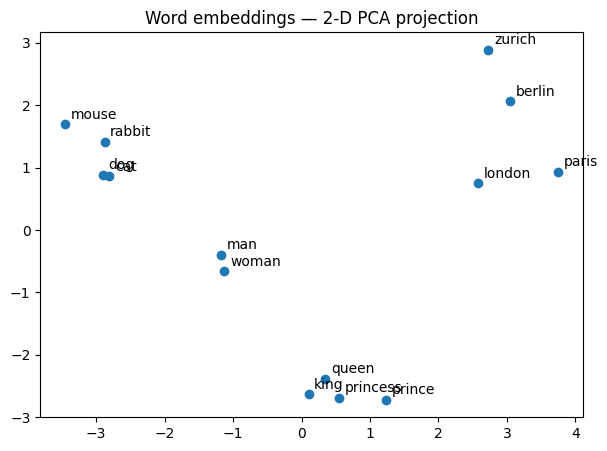

In [16]:
# Visualize a 2-D projection of selected words
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

words = ["king", "queen", "man", "woman", "prince", "princess",
         "cat", "dog", "rabbit", "mouse",
         "paris", "london", "berlin", "zurich"]
vectors = np.array([wv[w] for w in words])
xy = PCA(n_components=2).fit_transform(vectors)

plt.figure(figsize=(7, 5))
plt.scatter(xy[:, 0], xy[:, 1])
for (x, y), w in zip(xy, words):
    plt.annotate(w, (x, y), xytext=(4, 4), textcoords="offset points")
plt.title("Word embeddings — 2-D PCA projection"); plt.show()

### Vector Math

For some, a fun game to play is vector math.

This allows us to validate the performance of our embedding model and check whether it aligns to our intuition about words and their meaning.

In [17]:
from __future__ import annotations
import re
import numpy as np


def analogy(wv, equation: str, topn: int = 10) -> list[tuple[str, float]]:
    """Solve a word-vector arithmetic equation and return the closest words.

    Adapted from Gensim's source code:
    https://github.com/piskvorky/gensim/blob/37f90ec121eb7cd401448a947e80953e0c53ccdc/gensim/models/keyedvectors.py#L778

    Parameters
    ----------
    wv :
        A gensim `KeyedVectors` object (e.g. the result of
        ``gensim.downloader.load("glove-wiki-gigaword-50")``). We only rely on
        a handful of its attributes:
          - ``wv[word]``        -> the raw 1-D vector for a word
          - ``wv.vectors``      -> a 2-D array (vocab_size x vector_size) of all vectors
          - ``wv.vector_size``  -> length of a single vector
          - ``wv.index_to_key`` -> list mapping row index -> word
          - ``wv.key_to_index`` -> dict mapping word -> row index
    equation :
        An arithmetic expression over words, e.g. ``"king - man + woman"``.
        A leading term with no sign is treated as positive.
    topn :
        How many results to return.

    Returns
    -------
    list of (word, similarity), sorted from most to least similar.
    """

    # ------------------------------------------------------------------
    # Step 1: Parse the equation into (sign, word) terms.
    #
    # The regex grabs an optional leading + or -, then a run of letters.
    # "king - man + woman" -> [("", "king"), ("-", "man"), ("+", "woman")]
    # A missing sign (the first term) defaults to "+".
    # ------------------------------------------------------------------
    terms = re.findall(r"([+-]?)\s*([A-Za-z]+)", equation)
    if not terms:
        raise ValueError(f"Could not parse any words out of: {equation!r}")

    words: list[str] = []
    weights: list[float] = []
    for sign, word in terms:
        words.append(word.lower()) # GloVe wiki-gigaword vocab is lowercase
        weights.append(-1.0 if sign == "-" else +1.0)

    # ------------------------------------------------------------------
    # Step 2: Build the "mean" vector.
    #
    # gensim calls get_mean_vector(..., pre_normalize=True, post_normalize=True).
    # pre_normalize  -> use each word's *direction* only (divide out its length),
    #                   so frequent/long vectors don't dominate the sum.
    # We then scale by the sign (+1 / -1) and accumulate.
    # ------------------------------------------------------------------
    mean = np.zeros(wv.vector_size, dtype=np.float64)
    for word, weight in zip(words, weights):
        vec = wv[word]                       # raises KeyError if word not in vocab
        vec = vec / np.linalg.norm(vec)      # pre-normalize to a unit vector
        mean += weight * vec

    # post_normalize -> make the combined result a unit vector too. This is what
    # lets the dot product below act as a pure cosine similarity.
    mean /= np.linalg.norm(mean)

    # ------------------------------------------------------------------
    # Step 3: Cosine similarity against the whole vocabulary at once.
    #
    # cosine(a, b) = (a . b) / (|a| * |b|).
    # `mean` is already unit-length (|mean| = 1), so we only need to divide by
    # the norm of each vocabulary vector.
    # The matrix-vector dot does all words in one vectorized operation.
    # ------------------------------------------------------------------
    vocab_norms = np.linalg.norm(wv.vectors, axis=1)          # shape: (vocab_size,)
    sims = wv.vectors.dot(mean) / vocab_norms                 # shape: (vocab_size,)

    # ------------------------------------------------------------------
    # Step 4: Rank, and drop the words that were in the equation.
    #
    # ------------------------------------------------------------------

    # to avoid input words in the analogy "answer", get their vocabulary indices so we can skip them in the ranking
    input_indices = {wv.key_to_index[w] for w in words if w in wv.key_to_index}

    # argsort gives ascending order, so reverse it to make is descending (most similar to least)
    ranking = np.argsort(sims)[::-1] # indices, most-similar first

    # ------------------------------------------------------------------
    # Step 5: Gather the results
    #
    # ------------------------------------------------------------------
    results: list[tuple[str, float]] = []
    for idx in ranking:
        if idx in input_indices:
            continue
        results.append((wv.index_to_key[idx], float(sims[idx])))
        if len(results) >= topn:
            break

    return results

In [19]:
for word, score in analogy(wv, "king - man + woman", 10):
   print(f"{word:<15} {score:.4f}")

queen           0.8524
throne          0.7664
prince          0.7592
daughter        0.7474
elizabeth       0.7460
princess        0.7425
kingdom         0.7337
monarch         0.7214
eldest          0.7185
widow           0.7099


In [20]:
for word, score in analogy(wv, "Paris - France + Italy"):
   print(f"{word:<15} {score:.4f}")

rome            0.8466
milan           0.7766
turin           0.7666
venice          0.7592
madrid          0.7566
italian         0.7514
aires           0.7429
naples          0.7406
buenos          0.7357
lisbon          0.7245


In [21]:
# Same again, but with the build in method from Gensim :)
wv.most_similar(positive=["king", "woman"], negative=["man"], topn=3)

[('queen', 0.8523604273796082),
 ('throne', 0.7664334177970886),
 ('prince', 0.7592144012451172)]

👉 **Your turn** — What analogy relations can you find? Can you break it?

In [19]:
# Your code here...


## Sentence embeddings — one vector per sentence

As we mentioned in the slides, one naive way to build a sentence vector would be to simply retrieve the word embeddings for a given sentence and average them.

Let's explore this...

In [21]:
import spacy
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

nlp = spacy.load("en_core_web_sm")

def get_sentence_embedding(sentence, wv, nlp):
    """
    Computes a naive sentence embedding by averaging its constituent word embeddings.

    Args:
        sentence (str): The input sentence.
        wv (gensim.models.keyedvectors.KeyedVectors): Word embeddings model.
        nlp (spacy.lang.en.English): spaCy language model for tokenization.

    Returns:
        np.ndarray: The averaged sentence embedding. Returns a zero vector if no words are found.
    """
    # Tokenize and lowercase the sentence
    doc = nlp(sentence.lower())

    # Collect the embeddings from the pre-trained GloVe model
    word_vectors = []
    for token in doc:
        if token.is_alpha and token.text in wv:
            word_vectors.append(wv[token.text])

    # Handle edge cases
    if word_vectors:
        return np.mean(word_vectors, axis=0)
    else:
        return np.zeros(wv.vector_size) # Return a zero vector if no words are found

sentence_pairs = [
    ("The cat sat on the mat.", "A kitty was sitting on the small carpet."),
    ("The king ruled his kingdom wisely.", "The monarch governed his realm prudently."),
    ("The food was good.", "The food was not good."),
    ("No I am good.", "I am no good."),
    ("I went to the bank to deposit money.", "I went to the river bank to fish."),
    ("l loove thaat", "I love that"),
]

# Compute embeddings for all sentences
sentence_pairs_embeddings = []
for sentence_pair in sentence_pairs:
    s1_embedding = get_sentence_embedding(sentence_pair[0], wv, nlp)
    s2_embedding = get_sentence_embedding(sentence_pair[1], wv, nlp)
    sentence_pairs_embeddings.append((s1_embedding, s2_embedding))

print("Sentence Pairs:\n")
for i, (s1_embedding, s2_embedding) in enumerate(sentence_pairs_embeddings, 0):
    similarity = cosine_similarity([s1_embedding, s2_embedding])
    print(f"sim: {similarity[0][1]:.3f} {sentence_pairs[i][0]} vs. {sentence_pairs[i][1]}\n")

Sentence Pairs:

sim: 0.941 The cat sat on the mat. vs. A kitty was sitting on the small carpet.

sim: 0.893 The king ruled his kingdom wisely. vs. The monarch governed his realm prudently.

sim: 0.992 The food was good. vs. The food was not good.

sim: 1.000 No I am good. vs. I am no good.

sim: 0.957 I went to the bank to deposit money. vs. I went to the river bank to fish.

sim: -0.005 l loove thaat vs. I love that



### Comprehension Questions

1. Where does this approach work and where does it fail and why?

In [22]:
from sentence_transformers import SentenceTransformer, util

model = SentenceTransformer("sentence-transformers/all-mpnet-base-v2") # a strong-performing sentence transformer model

sentence_pairs_embeddings = []
for sentence_pair in sentence_pairs:
    s1_embedding = model.encode(sentence_pair[0])
    s2_embedding = model.encode(sentence_pair[1])
    sentence_pairs_embeddings.append((s1_embedding, s2_embedding))

for i, (s1_embedding, s2_embedding) in enumerate(sentence_pairs_embeddings, 0):
    similarity = cosine_similarity([s1_embedding, s2_embedding])
    print(f"sim: {similarity[0][1]:.3f} {sentence_pairs[i][0]} vs. {sentence_pairs[i][1]}\n")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

... (3 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

sim: 0.709 The cat sat on the mat. vs. A kitty was sitting on the small carpet.

sim: 0.786 The king ruled his kingdom wisely. vs. The monarch governed his realm prudently.

sim: 0.564 The food was good. vs. The food was not good.

sim: 0.711 No I am good. vs. I am no good.

sim: 0.500 I went to the bank to deposit money. vs. I went to the river bank to fish.

sim: 0.503 l loove thaat vs. I love that



### Comprehension Questions

1. Compare the results of the naive sentence embedding approach and the end-to-end Sentence Transformers approach. What do you notice about the similarity scores for each sentence pair?

👉 **Your turn**

1. Write 3–4 sentences of your own (mix two topics) and check whether the similarity matrix groups them the way you'd expect.

2. Try multilingual sentence pairs (e.g. English and German). For multilingual similarity, swap in `paraphrase-multilingual-MiniLM-L12-v2`.

For a full list of available pre-trained sentence transformer models, [see here](https://www.sbert.net/docs/sentence_transformer/pretrained_models.html)

In [23]:
my_sentences = [
    # your sentences here ...
]